### Practice 5 - Notebook 2
# Applications of Clustering and PCA - Exercise 5
## Semi-Supervised Learning: 20 and 100 Labels

**Teacher's task:** Repeat Section 3 with 20 and 100 labels. Does the gap between the first images and the representative images grow or shrink?

This notebook follows the original Section 3 comparison:
- **First images:** use the first *n* training images as the labeled examples.
- **Representative images:** use K-Means to select the image closest to each of *n* cluster centroids.
- Train the same classifier on each labeled set and compare test accuracy on the same held-out test set.

The conclusion is based on the actual results printed by the code, not hard-coded example values.

## 1. Import libraries

We use the Digits dataset, K-Means to select representative images, and Logistic Regression as the classifier.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression

## 2. Load the Digits dataset

As in Section 3, use the first 1,400 images for training and the remaining images for testing.

In [2]:
X_digits, y_digits = load_digits(return_X_y=True)

X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test = X_digits[1400:], y_digits[1400:]

print("Training images:", len(X_train))
print("Test images:", len(X_test))
print("Features per image:", X_train.shape[1])

Training images: 1400
Test images: 397
Features per image: 64


## 3. Define the evaluation function

The model is evaluated on `X_test`, which is held out from training. This gives a fair comparison between the two labeled-image selection strategies.

In [3]:
def test_accuracy(X_labeled, y_labeled):
    model = LogisticRegression(max_iter=10_000)
    model.fit(X_labeled, y_labeled)
    return model.score(X_test, y_test)

## 4. Compare the first images with K-Means representatives

For each label budget (20 and 100), we:
1. Train using the first *n* training images.
2. Fit K-Means with *n* clusters.
3. Select the training image closest to each cluster centroid.
4. Train and evaluate the same classifier for both sets.

In [4]:
def compare_methods(n, show_images=False):
    # Method A: the first n training images
    first_indices = np.arange(n)
    first_accuracy = test_accuracy(X_train[first_indices], y_train[first_indices])

    # Method B: one representative image per K-Means cluster
    kmeans = KMeans(n_clusters=n, random_state=42, n_init=10)
    distances = kmeans.fit_transform(X_train)
    representative_indices = distances.argmin(axis=0)

    # Ensure the selected representatives are unique; if a rare duplicate occurs,
    # keep the closest distinct images to the centroids.
    if len(np.unique(representative_indices)) < n:
        chosen = []
        used = set()
        for cluster_id in range(n):
            for idx in np.argsort(distances[:, cluster_id]):
                idx = int(idx)
                if idx not in used:
                    chosen.append(idx)
                    used.add(idx)
                    break
        representative_indices = np.array(chosen)

    representative_accuracy = test_accuracy(
        X_train[representative_indices],
        y_train[representative_indices]
    )

    gap = representative_accuracy - first_accuracy

    print(f"Number of labeled images: {n}")
    print(f"First {n} images accuracy:          {first_accuracy:.2%}")
    print(f"{n} representative images accuracy: {representative_accuracy:.2%}")
    print(f"Accuracy gap (representatives - first): {gap:+.2%}")
    print()

    if show_images:
        fig, axes = plt.subplots(2, n, figsize=(min(16, n * 0.45), 3.2))
        for ax, idx in zip(axes[0], first_indices):
            ax.imshow(X_train[idx].reshape(8, 8), cmap="binary")
            ax.axis("off")
        for ax, idx in zip(axes[1], representative_indices):
            ax.imshow(X_train[idx].reshape(8, 8), cmap="binary")
            ax.axis("off")
        axes[0, 0].set_ylabel("First images", fontsize=9)
        axes[1, 0].set_ylabel("K-Means reps", fontsize=9)
        fig.suptitle(f"Comparison with {n} labeled images")
        plt.tight_layout()
        plt.show()

    return {
        "n": n,
        "first_accuracy": first_accuracy,
        "representative_accuracy": representative_accuracy,
        "gap": gap,
    }

results_20 = compare_methods(20)
results_100 = compare_methods(100)

Number of labeled images: 20
First 20 images accuracy:          70.78%
20 representative images accuracy: 83.12%
Accuracy gap (representatives - first): +12.34%

Number of labeled images: 100
First 100 images accuracy:          80.86%
100 representative images accuracy: 88.92%
Accuracy gap (representatives - first): +8.06%



## 5. Compare the gap

The gap is defined as:

`representative-images accuracy − first-images accuracy`

A positive gap means the representative images performed better. We compare the **absolute size** of the gap at 20 and 100 labels to see whether it grew or shrank.

In [5]:
gap_20 = abs(results_20["gap"])
gap_100 = abs(results_100["gap"])

print(f"Absolute accuracy gap with 20 labels:  {gap_20:.2%}")
print(f"Absolute accuracy gap with 100 labels: {gap_100:.2%}")

if gap_100 < gap_20:
    conclusion = "The absolute accuracy gap shrank when increasing the label budget from 20 to 100."
elif gap_100 > gap_20:
    conclusion = "The absolute accuracy gap grew when increasing the label budget from 20 to 100."
else:
    conclusion = "The absolute accuracy gap stayed the same."

print("\nConclusion:", conclusion)

Absolute accuracy gap with 20 labels:  12.34%
Absolute accuracy gap with 100 labels: 8.06%

Conclusion: The absolute accuracy gap shrank when increasing the label budget from 20 to 100.


## 6. Visualize the measured accuracies

This chart uses the accuracy values calculated above. No values are manually entered.

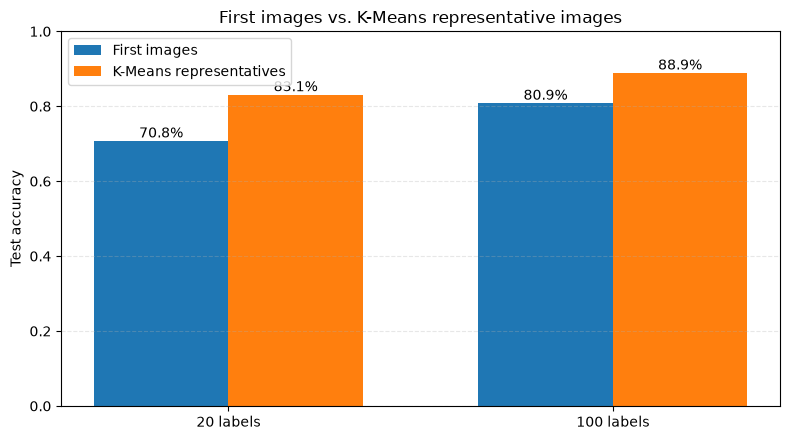

In [6]:
labels = ["20 labels", "100 labels"]
first_scores = [results_20["first_accuracy"], results_100["first_accuracy"]]
representative_scores = [
    results_20["representative_accuracy"],
    results_100["representative_accuracy"],
]

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - width / 2, first_scores, width, label="First images")
ax.bar(x + width / 2, representative_scores, width, label="K-Means representatives")
ax.set_xticks(x, labels)
ax.set_ylim(0, 1)
ax.set_ylabel("Test accuracy")
ax.set_title("First images vs. K-Means representative images")
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", labels=[f"{v:.1%}" for v in bars.datavalues])

plt.tight_layout()
plt.show()

### Final Answer

With 20 labels, the first-images test accuracy was **70.78%**, and the representative-images test accuracy was **83.12%**.

With 100 labels, the first-images test accuracy was **80.86%**, and the representative-images test accuracy was **88.92%**.

The absolute gap **shrank** when increasing the number of labels from 20 to 100, decreasing from **12.34 percentage points** to **8.06 percentage points**.